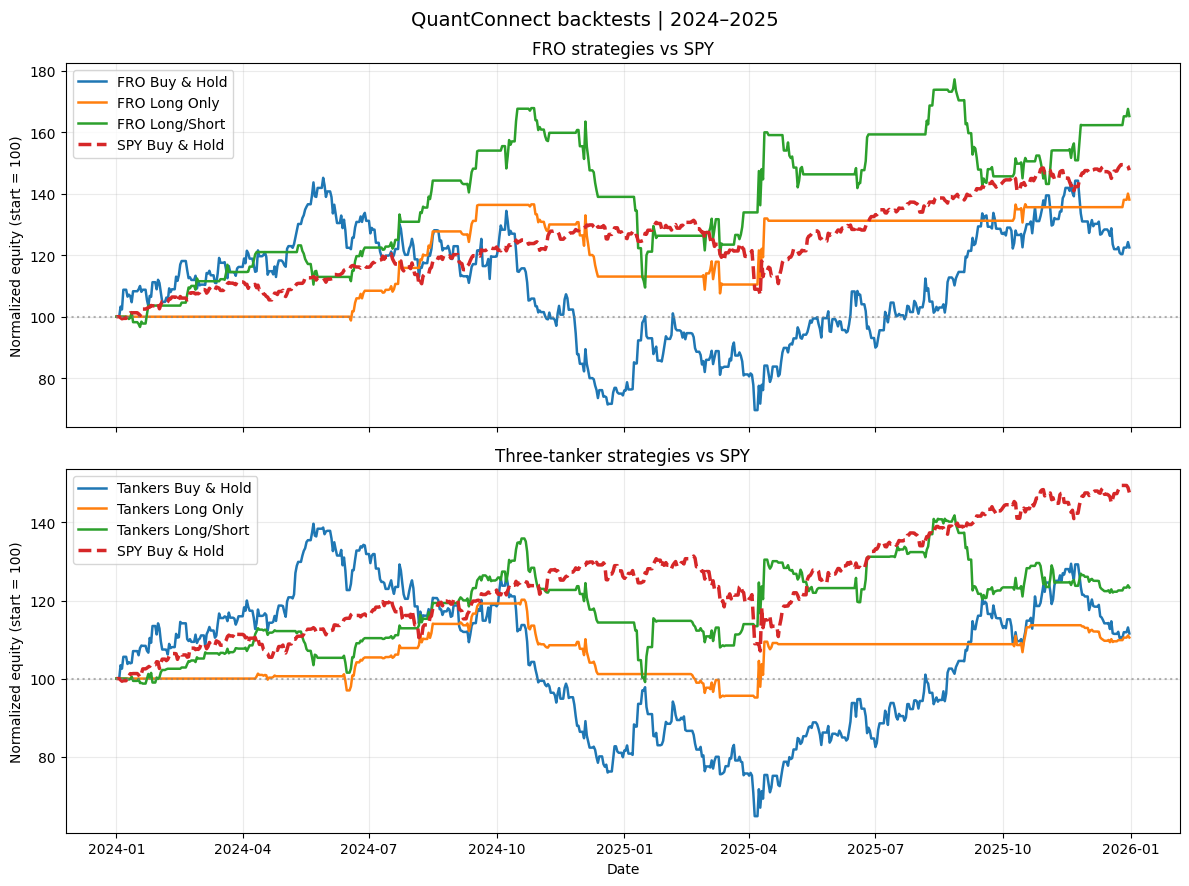

In [ ]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Notebook: ~/Desktop/applied financial technology/
# Results:  ~/Desktop/applied financial technology/assignment2_algorithms/
RESULTS_DIR = Path("assignment2_algorithms")

strategies = {
    "FRO Buy & Hold": "fro_buy_hold_results.json",
    "FRO Long Only": "fro_long_only_results.json",
    "FRO Long/Short": "fro_long_short_results.json",
    "Tankers Buy & Hold": "tankers_buy_hold_results.json",
    "Tankers Long Only": "tankers_long_only_results.json",
    "Tankers Long/Short": "tankers_long_short_results.json",
    "SPY Buy & Hold": "spy_buy_hold_results.json",
}

def load_equity_curve(filename):
    with (RESULTS_DIR / filename).open() as f:
        data = json.load(f)
    points = data["charts"]["Strategy Equity"]["series"]["Equity"]["values"]
    df = pd.DataFrame(points, columns=["timestamp", "open", "high", "low", "close"])
    df["date"] = pd.to_datetime(df["timestamp"], unit="s", utc=True).dt.normalize()
    daily = df.groupby("date")["close"].last().sort_index().astype(float)
    return daily / daily.iloc[0] * 100

equity = pd.DataFrame({name: load_equity_curve(filename)
                       for name, filename in strategies.items()})

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
comparisons = [
    ("FRO strategies vs SPY", ["FRO Buy & Hold", "FRO Long Only", "FRO Long/Short"]),
    ("Three-tanker strategies vs SPY", ["Tankers Buy & Hold", "Tankers Long Only", "Tankers Long/Short"]),
]
for ax, (title, names) in zip(axes, comparisons):
    for name in names:
        ax.plot(equity[name].index, equity[name], linewidth=1.8, label=name)
    ax.plot(equity["SPY Buy & Hold"].index, equity["SPY Buy & Hold"],
            linestyle="--", linewidth=2.5, label="SPY Buy & Hold")
    ax.axhline(100, linestyle=":", color="gray", alpha=0.6)
    ax.set(title=title, ylabel="Normalized equity (start = 100)")
    ax.grid(alpha=0.25)
    ax.legend(loc="best")
axes[-1].set_xlabel("Date")
fig.suptitle("QuantConnect backtests | 2024–2025", fontsize=14)
fig.tight_layout()
fig.savefig( "normalized_equity_curves.png", dpi=200, bbox_inches="tight")
plt.show()
